## Markowitz Porfolio Optimization

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('dark_background')

In [72]:
# À exécuter une fois si le paquet n'est pas installé :
# !pip install yfinance

import yfinance as yf

# Symboles boursiers (attention : Cisco utilise le ticker CSCO sur Yahoo Finance)
tickers = ['AAPL', 'CSCO', 'IBM', 'AMZN']

# Téléchargement des prix de clôture (ajuste les dates selon le besoin)
stocks = yf.download(tickers, start='2022-01-01', end='2026-01-01')['Close']

# Alignement de l'ordre et renommage des colonnes
stocks = stocks[['AAPL', 'CSCO', 'IBM', 'AMZN']]
stocks.columns = ['aapl', 'cisco', 'ibm', 'amzn']

[*********************100%***********************]  4 of 4 completed


In [73]:
stocks.tail()

,aapl,cisco,ibm,amzn
Date,,,,
2025-12-24,273.066711,76.601845,298.479675,232.380005
2025-12-26,272.657837,76.739296,298.999084,232.520004
2025-12-29,273.016876,76.376030,299.636139,232.070007
2025-12-30,272.338684,76.002945,296.019806,232.529999
2025-12-31,271.122009,75.629845,290.296387,230.820007


In [74]:
stocks.pct_change(1).mean()

aapl     0.000582
cisco    0.000425
ibm      0.001046
amzn     0.000579
dtype: float64

In [75]:
stocks.pct_change(1).corr()

,aapl,cisco,ibm,amzn
aapl,1.000000,0.483874,0.325893,0.560284
cisco,0.483874,1.000000,0.394812,0.412937
ibm,0.325893,0.394812,1.000000,0.229538
amzn,0.560284,0.412937,0.229538,1.000000


In [76]:
stocks.pct_change(1).head()

,aapl,cisco,ibm,amzn
Date,,,,
2022-01-03,NaN,NaN,NaN,NaN
2022-01-04,-0.012692,-0.024526,0.014555,-0.016916
2022-01-05,-0.026600,-0.015837,0.001449,-0.018893
2022-01-06,-0.016693,0.010617,-0.020836,-0.006711
2022-01-07,0.000988,0.003447,-0.003768,-0.004288


In [77]:
log_ret = np.log(stocks/stocks.shift(1))
log_ret.head()

,aapl,cisco,ibm,amzn
Date,,,,
2022-01-03,NaN,NaN,NaN,NaN
2022-01-04,-0.012773,-0.024832,0.014450,-0.017060
2022-01-05,-0.026960,-0.015963,0.001448,-0.019074
2022-01-06,-0.016834,0.010561,-0.021056,-0.006734
2022-01-07,0.000988,0.003441,-0.003775,-0.004297


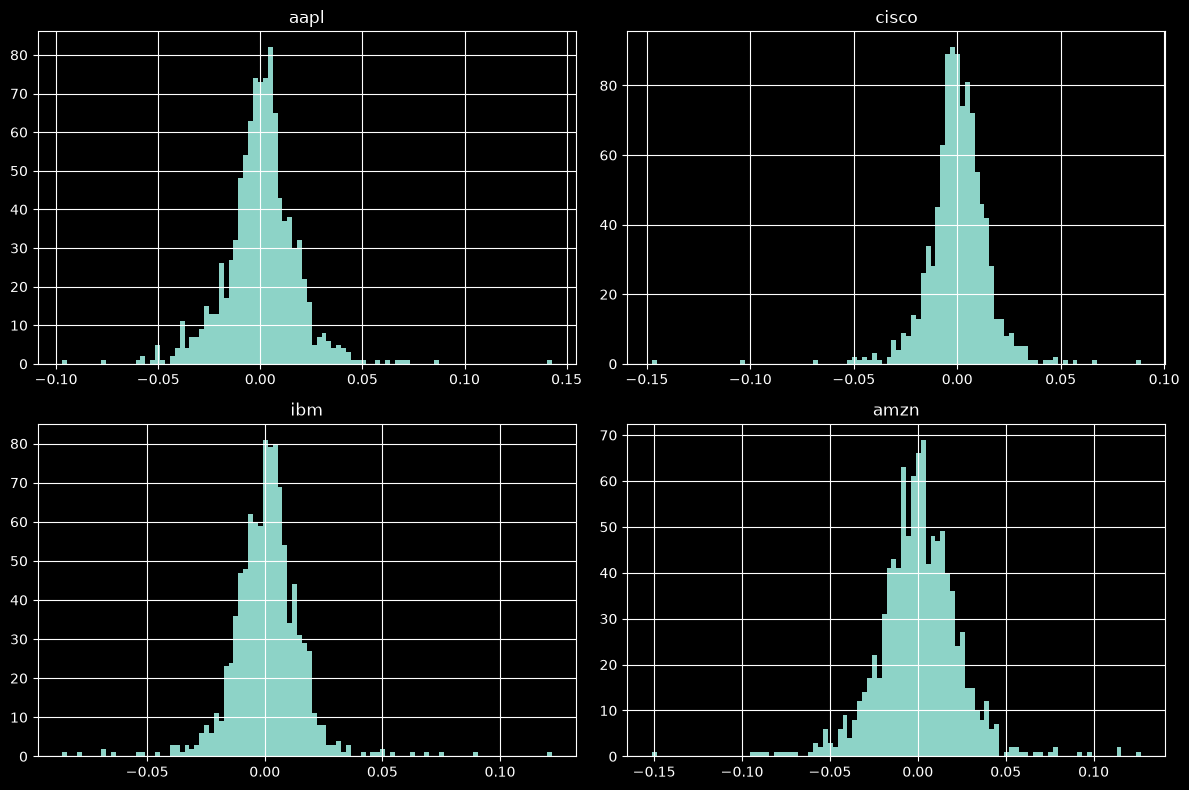

In [78]:
log_ret.hist(bins=100, figsize=(12,8))
plt.tight_layout()

In [79]:
log_ret.mean()

aapl     0.000421
cisco    0.000316
ibm      0.000934
amzn     0.000303
dtype: float64

In [80]:
log_ret.cov()*252

,aapl,cisco,ibm,amzn
aapl,0.080696,0.031973,0.022065,0.059565
cisco,0.031973,0.054872,0.021861,0.036012
ibm,0.022065,0.021861,0.056244,0.020565
amzn,0.059565,0.036012,0.020565,0.139526


In [81]:
np.random.seed(101)
num_ports = 5000
all_weights = np.zeros((num_ports, len(stocks.columns)))
ret_arr = np.zeros(num_ports)
vol_arr = np.zeros(num_ports)
sharpe_arr = np.zeros(num_ports)

for ind in range(num_ports) : 

    #Weights
    weights = np.array(np.random.random(4))
    weights = weights/np.sum(weights)

    #Save Weights
    all_weights[ind, :] = weights

    #Expected return 
    ret_arr[ind] = np.sum((log_ret.mean()*weights)*252)

    #Expected Vol

    vol_arr[ind] = np.sqrt(np.dot(weights.T, np.dot(log_ret.cov()*252, weights)))

    #Sharpe Ratio
    sharpe_arr[ind] = ret_arr[ind]/vol_arr[ind]


In [82]:
sharpe_arr.max()

np.float64(0.9661821395708622)

In [83]:
sharpe_arr.argmax()

np.int64(525)

In [84]:
all_weights[525, :]
max_sr_ret = ret_arr[525]
max_sr_vol = vol_arr[525]

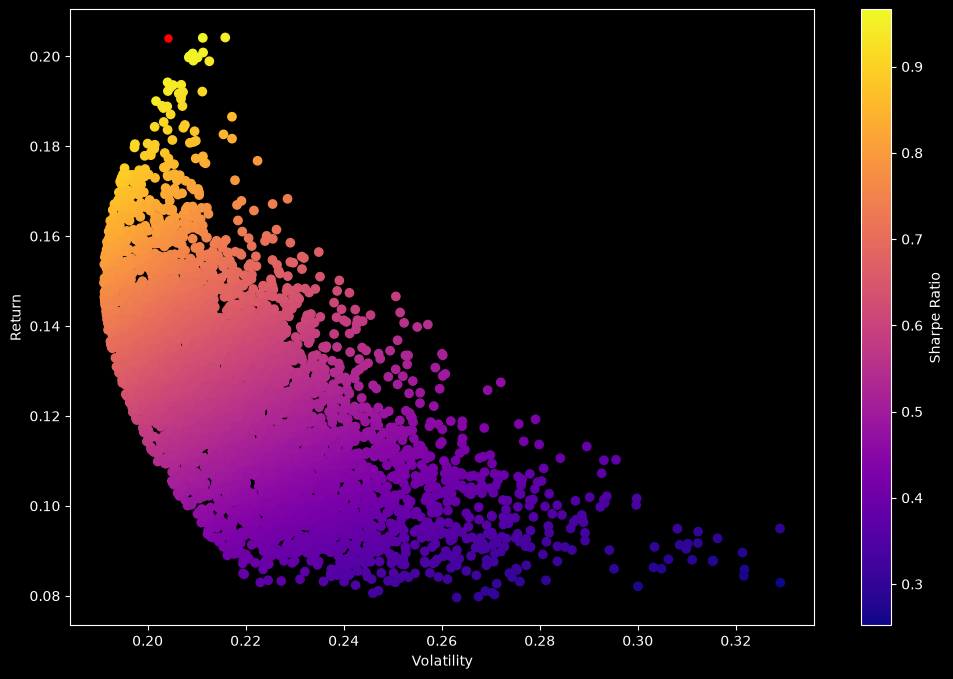

In [85]:
plt.figure(figsize=(12,8))
plt.scatter(vol_arr, ret_arr, c=sharpe_arr, cmap='plasma')
plt.colorbar(label='Sharpe Ratio')
plt.xlabel('Volatility')
plt.ylabel('Return')

plt.scatter(max_sr_ret, max_sr_ret, c='red', s=50, edgecolors='black')

In [86]:
#Mathematical Optimization

In [87]:
def get_rt_vol_sr(weights) :
    weights = np.array(weights)
    ret = np.sum(log_ret.mean()*weights)*252
    vol = np.sqrt(np.dot(weights.T, np.dot(log_ret.cov()*252, weights)))
    sr = ret/vol
    return np.array([ret, vol, sr])

In [88]:
from scipy.optimize import minimize

In [89]:
def neg_sharpe(weights) :
    return get_rt_vol_sr(weights)[2]*(-1)

In [90]:
def check_sum(weights):
    #return 0 if sum of weights is 1
    return np.sum(weights) -1

In [91]:
cons = ({'type' : 'eq', 'fun': check_sum})

In [92]:
bounds = ((0,1), (0,1), (0,1), (0,1))

In [93]:
init_guess = [0.25, 0.25, 0.25, 0.25]

In [94]:
opt_results = minimize(neg_sharpe, init_guess, method='SLSQP', bounds=bounds, constraints=cons)

In [95]:
opt_results

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: -0.9939377137760822
           x: [ 4.517e-02  0.000e+00  9.548e-01  4.608e-17]
         nit: 4
         jac: [ 9.686e-04  7.052e-02 -4.581e-05  8.556e-02]
        nfev: 20
        njev: 4
 multipliers: [ 2.909e-06]

In [96]:
opt_results.x

array([4.51715715e-02, 0.00000000e+00, 9.54828429e-01, 4.60837382e-17])

In [97]:
get_rt_vol_sr(opt_results.x)

array([0.22956563, 0.23096581, 0.99393771])

In [98]:
# Bornes correctes pour la grille de recherche
min_ret = (ret_arr.min())  # ou le rendement du portefeuille de variance minimale
max_ret = (ret_arr.max())  # le rendement de l'actif individuel le plus élevé

frontier_y = np.linspace(min_ret, max_ret, 100)

In [99]:
def minimize_vol(weights) :
    return get_rt_vol_sr(weights)[1]

In [100]:
frontier_vol = []
for possible_return in frontier_y :
    cons = ({'type': 'eq', 'fun': check_sum}, {'type' : 'eq', 'fun' : lambda w: get_rt_vol_sr(w)[0] -possible_return})

    result = minimize(minimize_vol, init_guess, method='SLSQP', bounds=bounds, constraints=cons)

    frontier_vol.append(result['fun'])

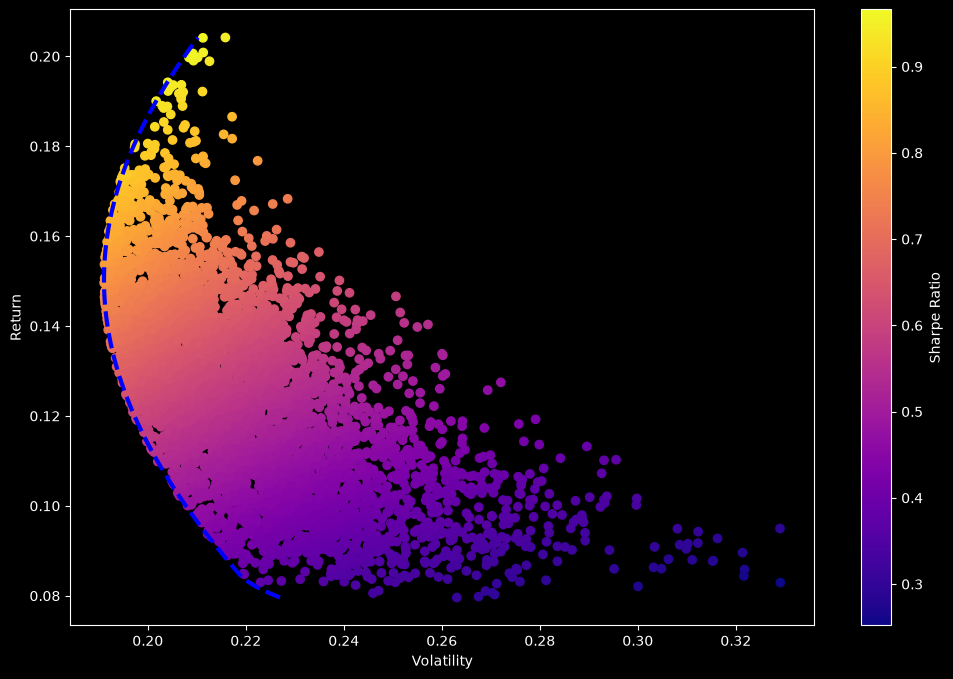

In [101]:
plt.figure(figsize=(12,8))
plt.scatter(vol_arr, ret_arr, c=sharpe_arr, cmap='plasma')
plt.colorbar(label='Sharpe Ratio')
plt.xlabel('Volatility')
plt.ylabel('Return')

plt.plot(frontier_vol, frontier_y, 'b--', linewidth=3)